# Stage 4: Chunking

Packs each article's elements into chunks of 400-800 tokens (cl100k) that follow the document's structure, puts
each image's description into the chunk where the image sits, and links every image record to its chunk.
Code: `src/handbook_qa/chunking.py` (rules in its docstring; decision 06).

Re-running: chunking is fast (well under a minute), so it always runs. It reads `data/build/articles.json`,
`data/build/images.jsonl` and the cached image descriptions, and writes `data/build/chunks.jsonl` and the updated
image index.

In [1]:
import collections
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from handbook_qa.chunking import build_index
from handbook_qa.config import load_settings

# Load settings and show limits
settings = load_settings()
paths = settings.paths
print("min / max tokens:", settings.chunks.min_tokens, "/", settings.chunks.max_tokens,
      "| overlap:", settings.chunks.overlap_sentences, "sentences, at most", settings.chunks.overlap_max_tokens, "tokens")
# Build chunks and the image index
print(build_index(settings))

# Load the built chunks and images
chunks = [json.loads(line) for line in paths.chunks.read_text(encoding="utf-8").splitlines()]
images = [json.loads(line) for line in paths.image_index.read_text(encoding="utf-8").splitlines()]
tokens = pd.Series([c["tokens"] for c in chunks])

min / max tokens: 400 / 800 | overlap: 2 sentences, at most 120 tokens


{'chunks': 859, 'images': 77, 'described': 77, 'undescribed': 0}


## Sizes

In [2]:
# Chunks per article and small chunks
per_article = collections.Counter(c["article_path"] for c in chunks)
small = [c for c in chunks if c["tokens"] < settings.chunks.min_tokens]
# Print size stats
print(tokens.describe(percentiles=[.1, .25, .5, .75, .9]).round().astype(int).to_string())
print(f"\nover {settings.chunks.max_tokens}: {(tokens > settings.chunks.max_tokens).sum()}")
print(f"under {settings.chunks.min_tokens}: {len(small)}, of which whole articles: "
      f"{sum(per_article[c['article_path']] == 1 for c in small)}")
print("chunks per article:", dict(sorted(collections.Counter(per_article.values()).items())))

count    859
mean     517
std      121
min       66
10%      368
25%      448
50%      514
75%      593
90%      692
max      768

over 800: 0
under 400: 113, of which whole articles: 20
chunks per article: {1: 75, 2: 57, 3: 45, 4: 20, 5: 15, 6: 11, 7: 5, 8: 6, 9: 6, 10: 3, 11: 4, 12: 1, 13: 2, 14: 2, 17: 1, 20: 1}


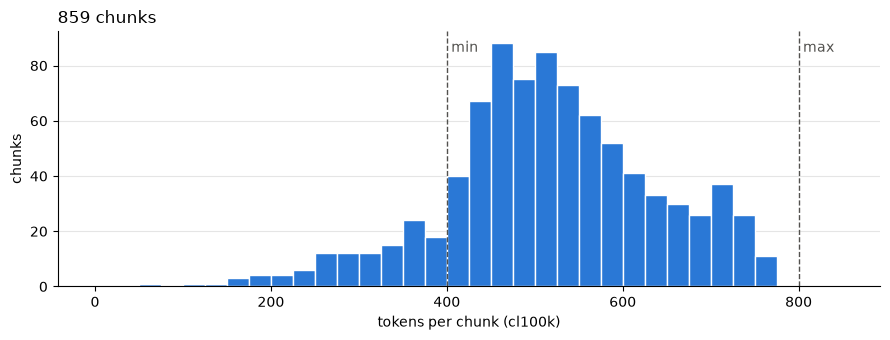

In [3]:
# Plot the chunk size histogram
SERIES_BLUE = "#2a78d6"
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(tokens, bins=np.arange(0, 851, 25), color=SERIES_BLUE, edgecolor="white", linewidth=1)
# Mark the min and max limits
for x, label in [(settings.chunks.min_tokens, "min"), (settings.chunks.max_tokens, "max")]:
    ax.axvline(x, color="#52514e", linewidth=1, linestyle="--")
    ax.text(x + 5, ax.get_ylim()[1] * 0.92, label, color="#52514e")
# Axis labels and styling
ax.set_xlabel("tokens per chunk (cl100k)")
ax.set_ylabel("chunks")
ax.set_title(f"{len(chunks)} chunks", loc="left")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()

## Invariants

Checked on the real output, not just in the unit tests.

In [4]:
# Map articles to their titles
article_titles = {}
for c in chunks:
    article_titles.setdefault(c["article_path"], c["article_title"])
# Invariant checks on the output
checks = {
    "no chunk over max_tokens": bool((tokens <= settings.chunks.max_tokens).all()),
    "every chunk starts with its article title": all(c["text"].startswith(c["article_title"]) for c in chunks),
    "chunk ids are unique": len({c["chunk_id"] for c in chunks}) == len(chunks),
    "every image placement is in exactly one chunk": sum(len(c["image_ids"]) for c in chunks)
                                                    == sum(len(i["occurrences"]) for i in images),
    "every image record links to a chunk": all(o["chunk_id"] for i in images for o in i["occurrences"]),
    "no chunk ends on a heading": all(not c["text"].rstrip().splitlines()[-1].startswith("#") for c in chunks),
}
pd.Series(checks)

no chunk over max_tokens                         True
every chunk starts with its article title        True
chunk ids are unique                             True
every image placement is in exactly one chunk    True
every image record links to a chunk              True
no chunk ends on a heading                       True
dtype: bool

## Where cuts fall

Most cuts land on headings (no overlap). When a cut falls inside a section, the next chunk repeats the last 1-2
sentences before it, marked with "…".

In [5]:
# Chunks that start with overlap
with_overlap = [c for c in chunks if c["overlap_tokens"]]
print(f"{len(with_overlap)} of {len(chunks)} chunks start with overlap; "
      f"overlap tokens: median {int(np.median([c['overlap_tokens'] for c in with_overlap]))}")
# Show one overlap example
example = with_overlap[0]
print(f"\n=== {example['chunk_id']} ({example['tokens']} tokens)\n{example['text'][:700]}")

23 of 859 chunks start with overlap; overlap tokens: median 22

=== company/communication#07 (526 tokens)
Communication
Section: Written communication > Slack
Source: contents/handbook/company/communication.md, pages 53-54

… #offsite-[team]-[month]-[year]-[where] - For planning and coordination of team offsite events

- #onboarding-[who]-[team]-[month]-[year]-[where] - For coordinating and supporting new team member onboarding
- #hiring-[team-name] - For recruiting discussions, candidate feedback, and hiring coordination for a specific team
- #superday-[first-name]-[role] - For candidate interview coordination and feedback during intensive interview days
On the very rare occasions you need to create a private channel for some reason - most commonly hiring-related - then it's probably worth stic


## A chunk with images

Each image becomes `[Image <id>, page N] caption description` at the place it appears. The ID is what the
answering model passes to `get_image` to see the picture.

In [6]:
# Find the chunk with the tier list
example = next(c for c in chunks if "img-p0041-x258" in c["image_ids"])
print(f"=== {example['chunk_id']} ({example['tokens']} tokens, pages {example['pages']})\n")
print(example["text"][:350], "\n...\n")
# Show the image placement
start = example["text"].index("[Image img-p0041-x258")
print(example["text"][start:start + 700])

=== company/brand-assets#04 (579 tokens, pages [40, 42])

Logos, brand, hedgehogs
Source: contents/handbook/company/brand-assets.md, pages 40-42

## Other fonts

We use two other fonts for special purposes. Please adhere to their usage guidelines listed below.

### Squeak

Squeak is used in informal settings, generally accompanied by hedgehog artwork.

#### Usage guidelines

- When used for headlines or a 
...

[Image img-p0041-x258, page 41] Communication tier list ranking PostHog communication methods from S tier to F tier. A tier list titled Communication tier list. S tier: Pull requests. A tier: Request for comments and GitHub issues. B tier: Public Slack channels. C tier: Carrier pigeon and Chemtrails. D tier: Private messages and Fax machine. E tier: Email. F tier: Tapping someone on the shoulder and saying, "You got a minute?". Each tier is a colored label with an icon. Some entries are jokes (carrier pigeon, chemtrails, fax machine). It ranks public, written, asynchronous chann

## Each image as its own record

Images are also items in their own right (`data/build/images.jsonl`), searched with their `retrieval_text` and
linked to the chunk they sit in.

In [7]:
# Find the p617 image record
record = next(i for i in images if i["image_id"] == "img-p0617-x2727")
# Show its fields and text
print(json.dumps({k: record[k] for k in ("image_id", "file", "width", "height")}, indent=1))
print("occurrences:", json.dumps(record["occurrences"][0] | {"text_before": "…", "text_after": "…"}, indent=1))
print("\nretrieval_text:\n" + record["retrieval_text"])

{
 "image_id": "img-p0617-x2727",
 "file": "data/build/images/img-p0617-x2727.png",
 "width": 1568,
 "height": 587
}
occurrences: {
 "article_path": "contents/handbook/growth/sales/new-hire-onboarding.md",
 "article_title": "New starter onboarding",
 "heading_path": [
  "New hire frequently asked questions",
  "How does my quota work during my ramp period?"
 ],
 "page": 617,
 "bbox": [
  50.25,
  46.5,
  561.73828125,
  237.74562072753906
 ],
 "text_before": "\u2026",
 "text_after": "\u2026",
 "chunk_id": "growth/sales/new-hire-onboarding#06"
}

retrieval_text:
Timeline of a new hire's ramp period for someone who joined 7/21/2025, showing Q3 and Q4 bonus rules.
Hand-drawn timeline from Q3 through Q4 to Q1. Example hire joined 7/21/2025. A three-month ramp-up bar spans 1st Aug to about 1st Nov. Q3 bonus (from 1st Aug to 1st Oct): 1 month not employed, 2 months 100% fixed OTE. Q4 bonus (1st Oct to 1st Dec): 1 month 100% fixed OTE, 2 months 'your attainment' OTE. Markers: 1st Aug, 1st Oct

## A table split by rows

Tables bigger than a chunk are split between rows, and each piece repeats the header row.

In [8]:
def table_headers(text: str) -> set[str]:
    """Header rows of the tables in a chunk (the row above each |---| separator)."""
    lines = text.splitlines()
    return {lines[i - 1] for i, line in enumerate(lines) if i and line.startswith("|---")}


# Find tables continuing in the next chunk
split = [(a, b, h) for a, b in zip(chunks, chunks[1:]) if a["article_path"] == b["article_path"]
         for h in table_headers(a["text"]) & table_headers(b["text"])]
print(len(split), "tables continue into the next chunk with their header repeated")
# Show two split examples
for a, b, header in split[:2]:
    print(f"\n{a['chunk_id']} -> {b['chunk_id']}\n  header: {header[:110]}")
    b_rows = [line for line in b["text"].splitlines() if line.startswith("|")]
    print("  next chunk starts its table with:\n   ", "\n    ".join(b_rows[:3])[:400])

6 tables continue into the next chunk with their header repeated

cs-and-onboarding/health-tracking#01 -> cs-and-onboarding/health-tracking#02
  header: |Measure|Poor|Concerning|Healthy|
  next chunk starts its table with:
    |Measure|Poor|Concerning|Healthy|
    |---|---|---|---|
    |Tickets created in last 30 days|>10|5-10|≤5|

cs-and-onboarding/health-tracking#02 -> cs-and-onboarding/health-tracking#03
  header: |Measure|Poor|Concerning|Healthy|
  next chunk starts its table with:
    |Measure|Poor|Concerning|Healthy|
    |---|---|---|---|
    |Event count last 30 days (percentage decrease)|>20%|5-20%|<= 5%|
